In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# importing sample data
X = np.array(([3, 5], [5, 1], [10, 2]), dtype = float)
y = np.array(([75], [82], [93]), dtype = float)

In [6]:
X = X / np.amax(X, axis = 0)
y = y / 100 # 100 is the max score  

In [7]:
X

array([[0.3, 1. ],
       [0.5, 0.2],
       [1. , 0.4]])

In [8]:
y

array([[0.75],
       [0.82],
       [0.93]])

In [91]:
class NeuralNetwork(object):
    def __init__(self):
        # hyperparameters
        self.inputLayerSize = 2
        self.hiddenLayerSize = 3
        self.outputLayerSize = 1
        
        # weights
        self.W1 = np.random.randn(self.inputLayerSize, self.hiddenLayerSize)
        self.W2 = np.random.randn(self.hiddenLayerSize, self.outputLayerSize)
        
    def forward(self, X):
        self.z2 = np.dot(X, self.W1)
        self.a2 = self.sigmoid(self.z2)
        self.z3 = np.dot(self.a2, self.W2)
        yHat = self.sigmoid(self.z3)
        return yHat 
    
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    def d_sigmoid(self, z):
        return np.exp(-z) / ((1 + np.exp(-z)) ** 2)
    
    def costFunction(self, X, y):
        yHat = self.forward(X)
        return 0.5 * np.sum((y - yHat) ** 2)
    
    def costFunctionPrime(self, X, y):
        self.yHat = self.forward(X)
        
        delta3 = np.multiply(-(y - self.yHat), self.d_sigmoid(self.z3))
        dJdW2 = np.dot(self.a2.T, delta3)
        
        delta2 = np.dot(delta3, self.W2.T) * self.d_sigmoid(self.z2)
        dJdW1 = np.dot(X.T, delta2)
        
        return dJdW1, dJdW2
    
    #defining helper functions
    def getParams(self): #returning the weights
        params = np.hstack((self.W1.ravel(), self.W2.ravel()))
        return params
        
    def setParams(self, params):
        W1_start = 0
        W1_end = self.hiddenLayerSize * self.inputLayerSize
        self.W1 = np.reshape(params[W1_start:W1_end], (self.inputLayerSize, self.hiddenLayerSize))
        W2_end = W1_end + self.hiddenLayerSize * self.outputLayerSize
        self.W2 = np.reshape(params[W1_end: W2_end], (self.hiddenLayerSize, self.outputLayerSize))
        
    def computeGradient(self, X, y):
        dJ1W1, dJ2W2 = self.costFunctionPrime(X, y)
        return np.concatenate((dJ1W1.ravel(), dJ2W2.ravel()))

In [10]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

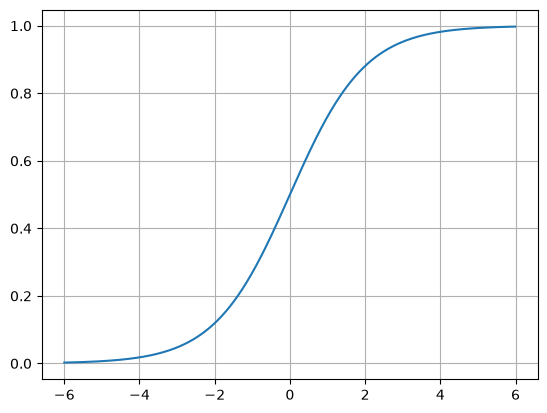

In [11]:
testInput = np.arange(-6, 6, .01)
plt.plot(testInput, sigmoid(testInput))
plt.grid(1)

In [12]:
sigmoid(np.random.randn(3, 3))

array([[0.54819266, 0.24350917, 0.40836   ],
       [0.33962839, 0.47318503, 0.63398138],
       [0.13159636, 0.54945612, 0.87794669]])

In [13]:
NN = NeuralNetwork()
yHat = NN.forward(X)

In [14]:
yHat

array([[0.61324796],
       [0.57150498],
       [0.57580985]])

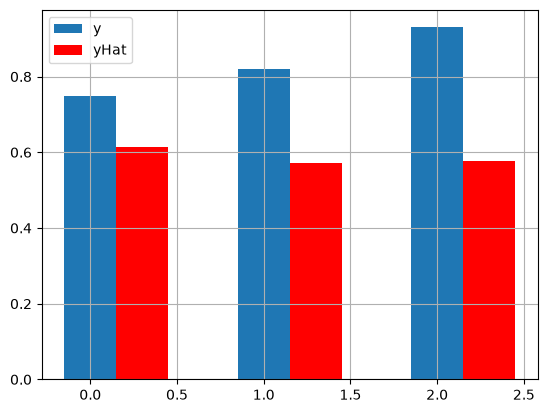

In [15]:
plt.bar([0, 1, 2], y.flatten(), width = 0.3)
plt.bar([0.3, 1.3, 2.3], yHat.flatten(), color = 'r', width = 0.3)
plt.grid(1)
plt.legend(['y', 'yHat'])

In [19]:
#implement a stochastic gradient descent

In [ ]:
NN = NeuralNetwork()
cost1 = NN.costFunction(X, y)
dJ1dw1, dJ2dw2 = NN.costFunctionPrime(X, y)

In [26]:
scalar = 3
NN.W1 = NN.W1 + scalar * dJ1dw1
NN.W2 = NN.W2 + scalar * dJ2dw2
cost2 = NN.costFunction(X, y)
print(cost1, cost2)

0.4148867910795837 0.6899688610576409


In [28]:
dJ1dw1, dJ2dw2 = NN.costFunctionPrime(X, y)

In [29]:
NN.W1 = NN.W1 - scalar * dJ1dw1
NN.W2 = NN.W2 - scalar * dJ2dw2
cost3 = NN.costFunction(X, y)
print(cost2, cost3)

0.6899688610576409 0.16811957242541342


In [83]:
a = np.array([[1, 2, 3, 4]])
b = np.array([[5, 6, 7, 8]])
# print(a.shape, b.shape)
# print(np.concatenate([a, b]), np.concatenate([a, b]).shape)
# print(np.concatenate((a, b)))
# c = np.concatenate([a, b.T], axis=1)
# print(c)
# d = np.hstack((a, b.T))
# print(d)
# concatenate, hstack, vstack, stack
e = np.hstack((a, b), dtype = float)
print(e, e.shape)

[[1. 2. 3. 4. 5. 6. 7. 8.]] (1, 8)


In [98]:
def computeGradients(N, X, y): #numerical gradient checking between the proper differtial methods and derivative equation 
    e = 1e-4
    paramsInitial = N.getParams()
    numgrad = np.zeros(paramsInitial.shape)
    perturb = np.zeros(paramsInitial.shape)
    
    for p in range(len(paramsInitial)):
        perturb[p] = e
        N.setParams(paramsInitial + perturb)
        loss2 = N.costFunction(X, y)
        N.setParams(paramsInitial - perturb)
        loss1 = N.costFunction(X, y)
        
        numgrad[p] = (loss2 - loss1) / (2 * e)
        perturb[p] = 0
    
    N.setParams(paramsInitial)
    return numgrad

In [99]:
N = NeuralNetwork()

In [100]:
numgrad = computeGradients(N, X, y)
numgrad

array([ 0.01885771,  0.0254986 ,  0.05822908,  0.0107728 ,  0.01803348,
        0.05108055, -0.23214261, -0.21724525, -0.09898181])

In [101]:
grad = N.computeGradient(X, y)
grad

array([ 0.01885771,  0.0254986 ,  0.05822908,  0.0107728 ,  0.01803348,
        0.05108055, -0.23214261, -0.21724525, -0.09898181])

In [102]:
np.linalg.norm(grad - numgrad)/np.linalg.norm(grad + numgrad)

np.float64(2.1133257255906164e-10)

In [1]:
from scipy import optimize #for running BFGS algorithm for minimization

In [ ]:
class trainer(object):
    def __init__(self, N):
        self.N = N
        
    def callbackF(self, params):
        self.N.setParams(params)
        self.